# code_021 · Learning failures and useful diagnostics

**Book:** Chapter 4, section 4.5. **Scope:** an inspectable learning-mechanism laboratory with locally generated data. These examples do not establish real structural safety, causal effects, generalization to new materials or a competitive model benchmark. They are not exhaustive estimator-constructor studies.

Use the [quickstart](../README.md) and [pinned environment](../requirements-lock.txt). Restart the kernel and run every cell in order. Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, scikit-learn 1.9.0, CPU only on macOS ARM64. All data/helpers/imports are inside this notebook. No ordinary-run files, network downloads, credentials, GPU or private imports are needed. Allow a minute to execute and 30–60 minutes to inspect predictions and exercises. Actual timing, versions and results appear at the end and in [execution evidence](../CHAPTER_04_EXECUTION.md).

Read each prediction prompt first. Parameter values, fitted state, model/training controls, sampling assumptions and decision criteria have different roles. The [traceability guide](../CHAPTER_04_GUIDE.md) maps these mechanisms and exercises; the [stable registry](../CODE_EXAMPLES.md#code_021) preserves this ID. Every fitted assessment example declares its information boundary; pure gradient and failure checks use constructed training data only.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from scipy import special
from IPython.display import display
START=time.perf_counter();SEED=421;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 421


<a id="flat-loss"></a>
## One flat curve, two different causes

Use noiseless y=.4+1.8*x on twenty fixed dimensionless x values with an affine design. A zero learning rate gives no parameter movement despite a nonzero true gradient. A separate deliberate bug reports a zero gradient. The loss itself still changes with parameter perturbations, so a finite-difference check catches the incorrect report. This simulates a gradient-flow error explicitly; it is not a claim to exercise an autodiff framework's detach internals.

**Predict:** which logged quantities distinguish a zero step from a zeroed gradient? Could a tiny nonzero step be hidden by coarse display precision?


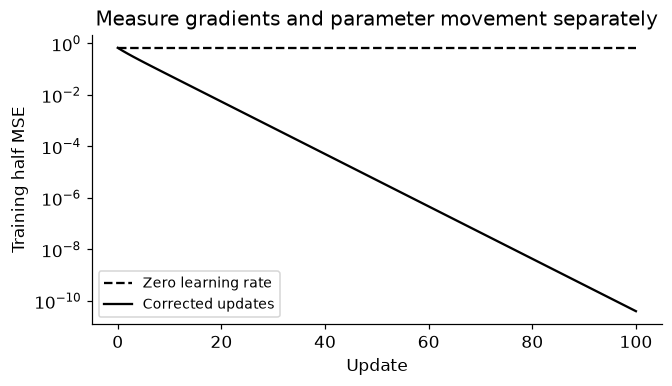

In [2]:
x=np.linspace(-1,1,20);X=np.column_stack([x,np.ones(len(x))]);y=.4+1.8*x
w0=np.zeros(2)
def value(X,y,w):return .5*np.mean((X@w-y)**2)
def grad(X,y,w):return X.T@(X@w-y)/len(y)
true_gradient=grad(X,y,w0);zero_rate_update=0.*true_gradient
reported_gradient=np.zeros(2);h=1e-5
numeric=np.array([(value(X,y,w0+h*e)-value(X,y,w0-h*e))/(2*h) for e in np.eye(2)])
assert np.linalg.norm(true_gradient)>.1 and np.allclose(zero_rate_update,0)
assert np.allclose(numeric,true_gradient,atol=1e-9) and not np.allclose(reported_gradient,numeric)
flat=[value(X,y,w0)]*101;w=w0.copy();healthy=[value(X,y,w)]
for _ in range(100):w=w-.3*grad(X,y,w);healthy.append(value(X,y,w))
reference=np.linalg.lstsq(X,y,rcond=None)[0]
assert value(X,y,w)<1e-9 and np.allclose(w,reference,atol=1e-4)
fig,ax=plt.subplots(figsize=(6,3.4));ax.semilogy(flat,'k--',label='Zero learning rate');ax.semilogy(np.maximum(healthy,1e-16),'k-',label='Corrected updates')
ax.set(xlabel='Update',ylabel='Training half MSE',title='Measure gradients and parameter movement separately');ax.legend(fontsize=9);plt.show()
RESULTS['zero_rate_gradient_norm']=float(np.linalg.norm(true_gradient));RESULTS['healthy_final_half_MSE']=float(value(X,y,w))


<a id="capacity"></a>
## A stationary model can still underfit

The second target is an exact quadratic y=.3+1.5*x+.8*x². An affine least-squares fit reaches its own optimum and has near-zero gradient, but retains systematic residuals. A quadratic feature gives enough capacity to fit this constructed rule exactly. This isolates representation from optimization; real residuals may also reflect measurement/data problems.

**Predict:** does running affine gradient descent longer make its function family contain x²?


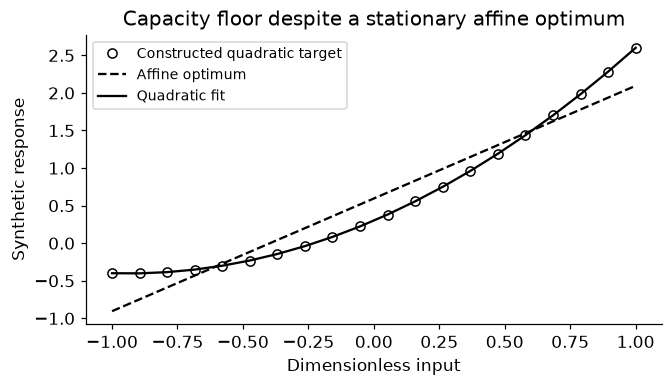

In [3]:
y_quad=.3+1.5*x+.8*x*x
linear=np.linalg.lstsq(X,y_quad,rcond=None)[0];quadratic_X=np.column_stack([x,x*x,np.ones(len(x))]);quadratic=np.linalg.lstsq(quadratic_X,y_quad,rcond=None)[0]
linear_loss=value(X,y_quad,linear);quadratic_loss=value(quadratic_X,y_quad,quadratic)
assert np.linalg.norm(grad(X,y_quad,linear))<1e-12 and linear_loss>.01 and quadratic_loss<1e-24
fig,ax=plt.subplots(figsize=(6,3.4));ax.plot(x,y_quad,'ko',mfc='white',label='Constructed quadratic target');ax.plot(x,X@linear,'k--',label='Affine optimum');ax.plot(x,quadratic_X@quadratic,'k-',label='Quadratic fit')
ax.set(xlabel='Dimensionless input',ylabel='Synthetic response',title='Capacity floor despite a stationary affine optimum');ax.legend(fontsize=9);plt.show()
RESULTS['affine_capacity_half_MSE']=float(linear_loss);RESULTS['quadratic_half_MSE']=float(quadratic_loss)


<a id="tiny-overfit"></a>
## Tiny-data fitting is not proof of correct labels

Eight distinct x values admit a degree-seven interpolating polynomial. Fit both the original targets and a permutation. Both achieve tiny training loss. This is a capacity/implementation probe, not an assessment of unseen behavior or a recommendation to deploy an interpolating polynomial. It also cannot establish that target identities are right.

**Predict:** why can passing a tiny-overfit check coexist with completely wrong row pairing?


In [4]:
small_x=np.linspace(-1,1,8);V=np.vander(small_x,8,increasing=True);small_y=np.sin(2*small_x)+rng.normal(0,.03,8)
permutation=rng.permutation(8);shuffled=small_y[permutation]
fit=np.linalg.lstsq(V,small_y,rcond=None)[0];wrong_fit=np.linalg.lstsq(V,shuffled,rcond=None)[0]
correct_error=np.max(abs(V@fit-small_y));shuffled_error=np.max(abs(V@wrong_fit-shuffled))
assert correct_error<1e-10 and shuffled_error<1e-10 and not np.allclose(small_y,shuffled)
print('Tiny fit max errors:',correct_error,shuffled_error,'but target identity differs.')
RESULTS['tiny_original_max_error']=float(correct_error);RESULTS['tiny_permuted_max_error']=float(shuffled_error)


Tiny fit max errors: 1.5543122344752192e-15 2.2315482794965646e-14 but target identity differs.


<a id="data-objective"></a>
## Data and objective checks before bigger training

A future-result feature is deliberately copied from the target. It would predict perfectly but is unavailable at the cutoff, so a timestamp ledger excludes it before training. A separate target scaling shows how unit changes alter squared loss numerically. Neither is solved by adding epochs. A semantic objective worksheet distinguishes estimating a mean from an upper quantile and a probability from a hard decision.


In [5]:
feature_ledger=pd.DataFrame({'field':['known_load','future_inspection_result'],'available_time':[0,2],'required_cutoff':[0,0]})
usable=feature_ledger.available_time<=feature_ledger.required_cutoff
assert feature_ledger.loc[usable,'field'].tolist()==['known_load']
leaked_prediction=y.copy();assert value(np.eye(len(y)),y,leaked_prediction)==0
loss_mm=value(X,y,w0);loss_m=value(X,y/1000,w0)
assert np.isclose(loss_m/loss_mm,1e-6)
worksheet=pd.DataFrame([
 ['mean deflection','squared error','gradient convergence does not make it an upper quantile'],
 ['upper .9 response quantile','pinball .9','verify held-out conditional/aggregate behavior'],
 ['finding probability','Bernoulli log loss with sigmoid','range validity does not establish calibration'],
 ['inspection decision','declared costs and capacity','a probability is not the chosen action']
],columns=['requested_output','appropriate_mechanism','diagnostic_boundary'])
assert len(worksheet)==4;display(feature_ledger);display(worksheet)
RESULTS['loss_unit_conversion_ratio']=float(loss_m/loss_mm)


,field,available_time,required_cutoff
0,known_load,0,0
1,future_inspection_result,2,0


,requested_output,appropriate_mechanism,diagnostic_boundary
0,mean deflection,squared error,gradient convergence does not make it an upper...
1,upper .9 response quantile,pinball .9,verify held-out conditional/aggregate behavior
2,finding probability,Bernoulli log loss with sigmoid,range validity does not establish calibration
3,inspection decision,declared costs and capacity,a probability is not the chosen action


<a id="exercises"></a>
## Exercises and optional hints

1. Replace zero rate with a tiny rate and log more digits plus update norms. Distinguish actual stagnation from display rounding.
2. Wrongly sum gradients rather than average them; change batch size and diagnose the altered effective step.
3. Introduce a nonfinite target, wrong target shape or mismatched IDs. Catch each before an optimizer call.
4. Compare affine and quadratic residuals, then add a measurement offset. State which hypotheses each experiment can separate.
5. Fit the tiny polynomial and evaluate a genuinely new sample only after predeclaring the rule. Do not equate memorization with useful generalization.
6. Write a diagnostic record with hypothesis, one change, observation and next investigation. Include metric, dataset and selection roles on every curve.

**Hints:** a zero gradient can indicate a valid optimum or a broken computation; a nonzero gradient with zero movement suggests a different set of causes. Tiny-data overfit success cannot certify targets, causal assumptions or final performance. Development-based stopping spends development information.

**Troubleshooting:** inspect the contract first, compare numerical and reported sensitivities, measure parameter movement and use simple reference fits. [Scikit-learn pitfalls](https://scikit-learn.org/1.9/common_pitfalls.html) describes information leakage and inconsistent preprocessing. These training-only diagnostic exercises are not a repeatedly tuned final benchmark.


In [6]:
summary={'example_id':'code_021','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['flat zero-step loss with nonzero gradients', 'reported versus true derivative', 'corrected training and reference optimum', 'capacity floor versus optimization failure', 'tiny-data memorization limitation', 'target availability and objective-role ledger'],
'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["flat zero-step loss with nonzero gradients", "reported versus true derivative", "corrected training and reference optimum", "capacity floor versus optimization failure", "tiny-data memorization limitation", "target availability and objective-role ledger"], "elapsed_seconds": 0.251, "example_id": "code_021", "hardware": "Darwin arm64 CPU", "results": {"affine_capacity_half_MSE": 0.03448665986295379, "healthy_final_half_MSE": 4.00387200678499e-11, "loss_unit_conversion_ratio": 1e-06, "quadratic_half_MSE": 1.3874519689987171e-31, "tiny_original_max_error": 1.5543122344752192e-15, "tiny_permuted_max_error": 2.2315482794965646e-14, "zero_rate_gradient_norm": 0.7744536095543749}, "seed": 421, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
